In [1]:
%pip install scikit-learn joblib matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 3.4 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 3.7 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 2.6 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 2.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 626.4 kB/s  0:00:11m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 374.5 kB/s  0:01:12m0:00:0100:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [2]:
#Đọc dữ liệu sạch và tách đặc trưng ($X$) cùng nhãn mục tiêu ($y$)
import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Đọc file dữ liệu sạch từ Nhiệm vụ 1
df = pd.read_csv('../data/processed/data_cleaned.csv')

# Chọn các cột đặc trưng (X)
feature_cols = [
    'Heart Rate',
    'Physical Activity Level',
    'Daily Steps',
    'Sleep Duration',
    'Stress Level',
    'bp_systolic',
    'bp_diastolic',
]

X = df[feature_cols]

# Nhãn mục tiêu (y) là điểm chất lượng giấc ngủ (0 - 100)
y = df['sleep_quality_score']

print('Kích thước tập X:', X.shape)
print('Kích thước nhãn y:', y.shape)
X.head()

Kích thước tập X: (374, 7)
Kích thước nhãn y: (374,)


,Heart Rate,Physical Activity Level,Daily Steps,Sleep Duration,Stress Level,bp_systolic,bp_diastolic
0,77,42,4200,6.1,6,126,83
1,75,60,10000,6.2,8,125,80
2,75,60,10000,6.2,8,125,80
3,85,30,3000,5.9,8,140,90
4,85,30,3000,5.9,8,140,90


In [3]:
#Chia tập Train / Test và chuẩn hóa đặc trưng (Scaling)

# 1. Chia tập Train/Test với tỷ lệ 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Khởi tạo bộ chuẩn hóa StandardScaler
scaler = StandardScaler()

# Fit và Transform trên tập Train; chỉ Transform trên tập Test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Lưu bộ chuẩn hóa để Dashboard hoặc Edge sử dụng khi có dữ liệu mới
joblib.dump(scaler, '../models/scaler.pkl')
print('-> Đã lưu bộ chuẩn hóa vào: models/scaler.pkl')

-> Đã lưu bộ chuẩn hóa vào: models/scaler.pkl


In [4]:
#Huấn luyện mô hình Random Forest Baseline
# Khởi tạo mô hình Random Forest Baseline
rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=10, random_state=42
)

# Huấn luyện mô hình trên tập Train
rf_model.fit(X_train_scaled, y_train)

print('Huấn luyện mô hình hoàn tất!')

Huấn luyện mô hình hoàn tất!


In [5]:
#Đánh giá mô hình trên tập kiểm thử (Test Set)
# Dự đoán trên tập Test
y_pred = rf_model.predict(X_test_scaled)

# Tính toán các chỉ số đánh giá
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST ---')
print(
    f'MAE (Sai số tuyệt đối trung bình): {mae:.2f} điểm (thang 0-100)'
)  # MAE càng nhỏ càng tốt
print(f'RMSE (Sai số căn phương trung bình): {rmse:.2f}')
print(f'R2 Score (Hệ số xác định): {r2:.4f}')  # R2 càng gần 1 càng tốt

# Hiển thị thử 5 kết quả so sánh giữa thực tế và dự đoán
comparison_df = pd.DataFrame(
    {'Điểm thực tế (Thật)': y_test.values[:5], 'Điểm dự đoán (AI)': y_pred[:5]}
)
comparison_df

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST ---
MAE (Sai số tuyệt đối trung bình): 0.44 điểm (thang 0-100)
RMSE (Sai số căn phương trung bình): 1.19
R2 Score (Hệ số xác định): 0.9906


,Điểm thực tế (Thật),Điểm dự đoán (AI)
0,90,90.0
1,60,60.0
2,60,60.0
3,90,90.0
4,60,60.0


-> Đã lưu mô hình thành công vào: ../models/sleep_rf_model.pkl


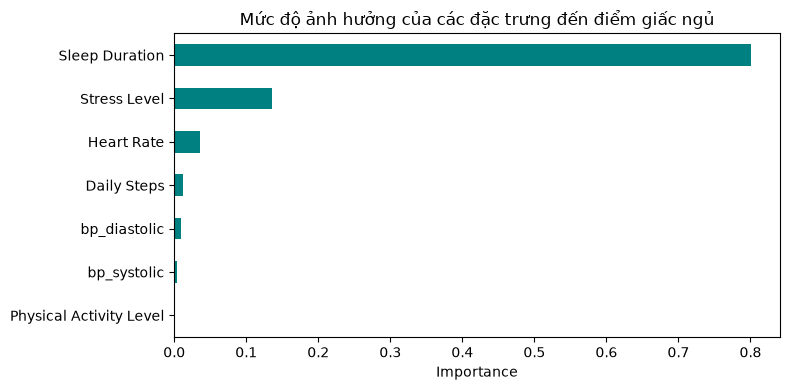

In [6]:
#Xuất file mô hình và đánh giá mức độ quan trọng của đặc trưng
import matplotlib.pyplot as plt

# 1. Lưu file mô hình vào thư mục models/
model_path = '../models/sleep_rf_model.pkl'
joblib.dump(rf_model, model_path)
print('-> Đã lưu mô hình thành công vào:', model_path)

# 2. Xem đặc trưng nào ảnh hưởng lớn nhất đến chất lượng giấc ngủ
importance = rf_model.feature_importances_
feat_importance = pd.Series(importance, index=feature_cols).sort_values(
    ascending=True
)

plt.figure(figsize=(8, 4))
feat_importance.plot(kind='barh', color='#008080')
plt.title('Mức độ ảnh hưởng của các đặc trưng đến điểm giấc ngủ')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()